In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

c:\Users\natha\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:110: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\natha\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 199, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\natha\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\natha\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\natha\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

Text(0.5, 1.0, 'Mood map: keyword centroids (bubble size = number of tracks)')

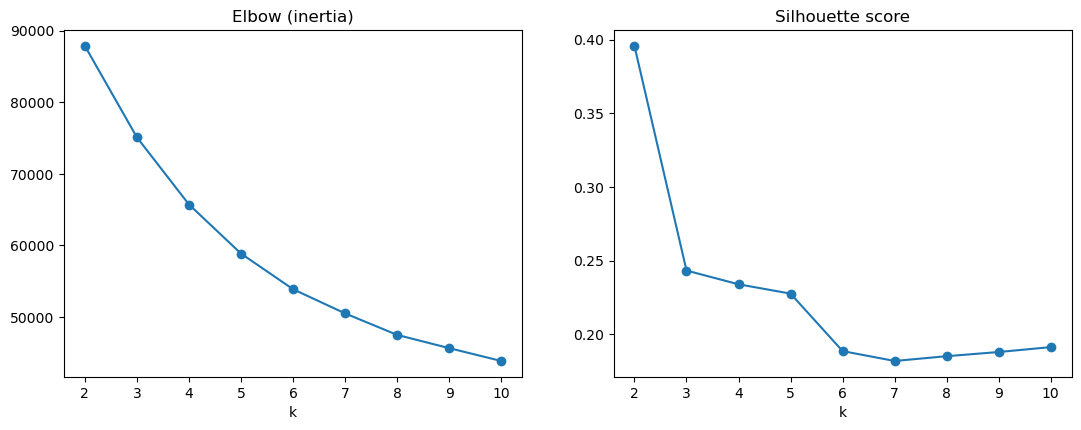

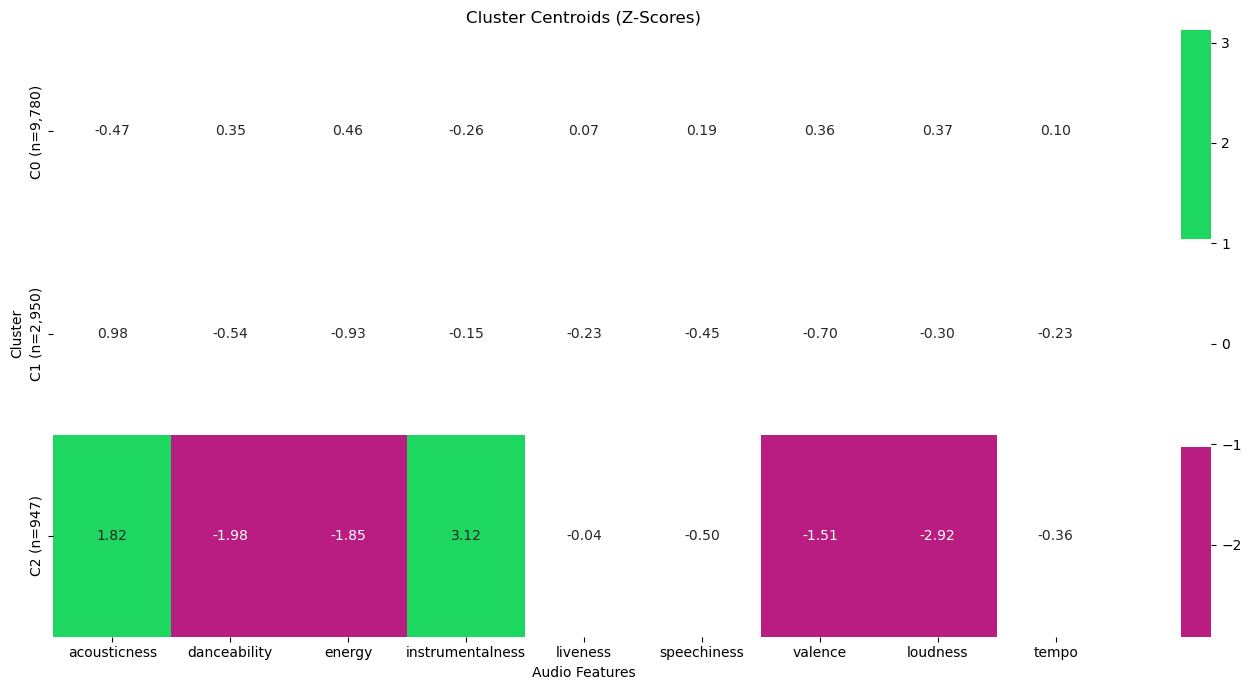

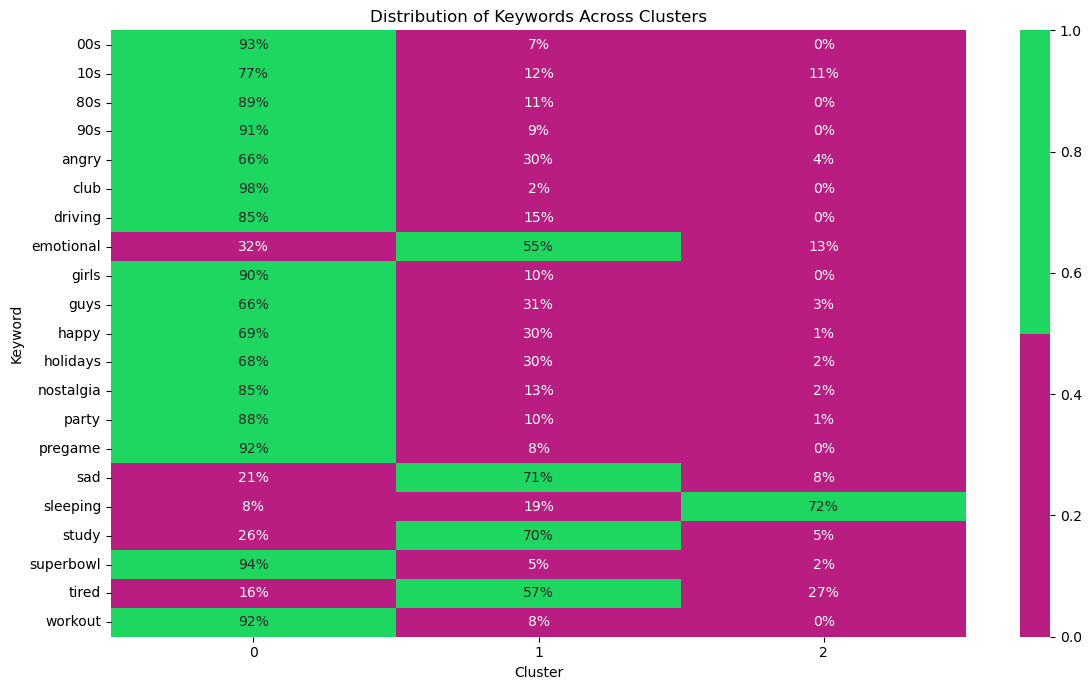

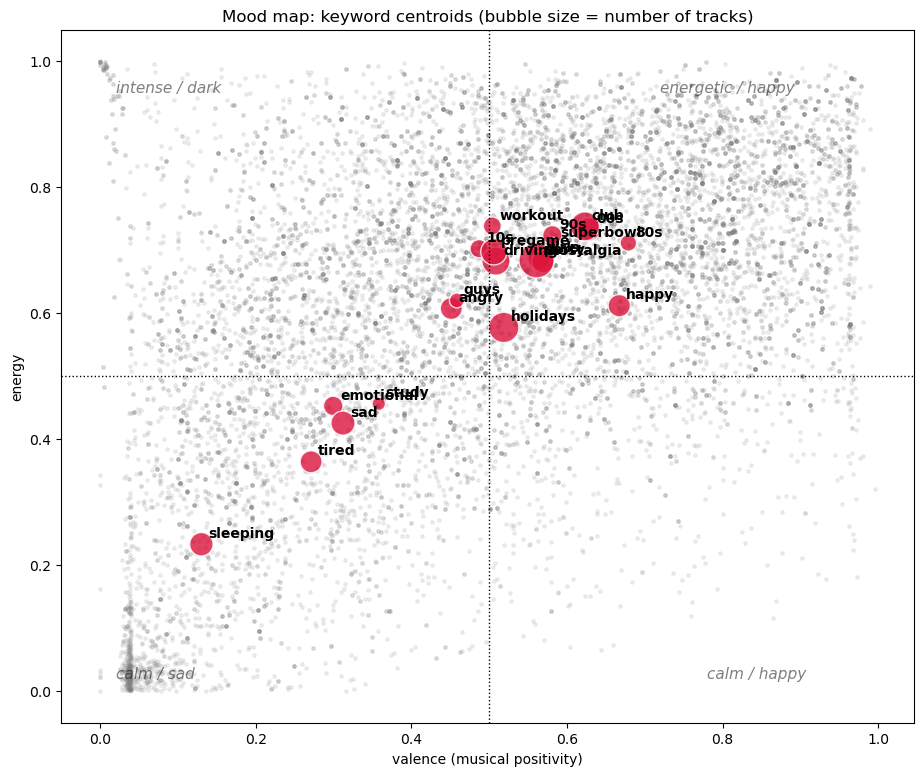

In [3]:

# Set up
DATA_PATH = "C:\\Users\\natha\\OneDrive\\Documents\\full_data.csv"
RANDOM_STATE=42
UNIT_FEATURES = ["acousticness", "danceability", "energy", "instrumentalness",
                 "liveness", "speechiness", "valence"]          
AUDIO_FEATURES = UNIT_FEATURES + ["loudness", "tempo"]   
df=pd.read_csv(DATA_PATH)
df_kw = df.drop_duplicates(["keyword", "track_id"])

X_df = df_kw.dropna(subset=AUDIO_FEATURES).reset_index(drop=True)
X = StandardScaler().fit_transform(X_df[AUDIO_FEATURES])

#Setting Up clustering algorithm and finiding best # of ks

ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_, sample_size=4000, random_state=RANDOM_STATE))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(list(ks), inertia, "o-")
axes[0].set_title("Elbow (inertia)")
axes[0].set_xlabel("k")
axes[1].plot(list(ks), sil, "o-")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("k")


sil_s = pd.Series(sil, index=list(ks))
best_k =  int(sil_s.loc[3:].idxmax())
km = KMeans(n_clusters=best_k, n_init=20, random_state=RANDOM_STATE).fit(X)
X_df["cluster"] = km.labels_

centers = pd.DataFrame(km.cluster_centers_, columns=AUDIO_FEATURES)
sizes = X_df.cluster.value_counts().sort_index()
centers.index = [f"C{i} (n={sizes[i]:,})" for i in centers.index]

raw_profile = X_df.groupby("cluster")[AUDIO_FEATURES + ["popularity"]].mean()



# Centroids for each cluster

plt.figure(figsize=(14, 7))

sns.heatmap(
    centers,
    annot=True,
    fmt=".2f",
    cmap=sns.color_palette(["#B91D82", "#FFFFFF", "#1ed760"], as_cmap=True),
    center=0
)

plt.title("Cluster Centroids (Z-Scores)")
plt.xlabel("Audio Features")
plt.ylabel("Cluster")
plt.tight_layout()


# Heatmap 2: Distribution of keywords across clusters
share = pd.crosstab(
    X_df.keyword,
    X_df.cluster,
    normalize="index"
)

plt.figure(figsize=(12, 7))

sns.heatmap(
    share,
    annot=True,
    fmt=".0%",
    cmap=sns.color_palette(["#B91D82", "#1ed760"], as_cmap=True),
    vmin=0,
    vmax=1
)

plt.title("Distribution of Keywords Across Clusters")
plt.xlabel("Cluster")
plt.ylabel("Keyword")
plt.tight_layout()

plt.figure(figsize=(11, 9))
bg = df_kw.dropna(subset=["valence", "energy"])
plt.scatter(bg.valence, bg.energy, s=6, alpha=0.12, color="grey")
cent = df_kw.groupby("keyword")[["valence", "energy"]].mean()
size = df_kw.groupby("keyword").size()
plt.scatter(cent.valence, cent.energy, s=size / size.max() * 600 + 40, c="crimson", alpha=0.8,
            edgecolor="white")
for kw, r in cent.iterrows():
    plt.annotate(kw, (r.valence, r.energy), xytext=(5, 5), textcoords="offset points", fontsize=10,
                 weight="bold")
plt.axvline(0.5, color="k", ls=":", lw=1)
plt.axhline(0.5, color="k", ls=":", lw=1)
for txt, (x, y) in {"calm / sad": (0.02, 0.02), "calm / happy": (0.78, 0.02),
                    "intense / dark": (0.02, 0.95), "energetic / happy": (0.72, 0.95)}.items():
    plt.text(x, y, txt, fontsize=11, alpha=0.5, style="italic")
plt.xlabel("valence (musical positivity)")
plt.ylabel("energy")
plt.title("Mood map: keyword centroids (bubble size = number of tracks)")



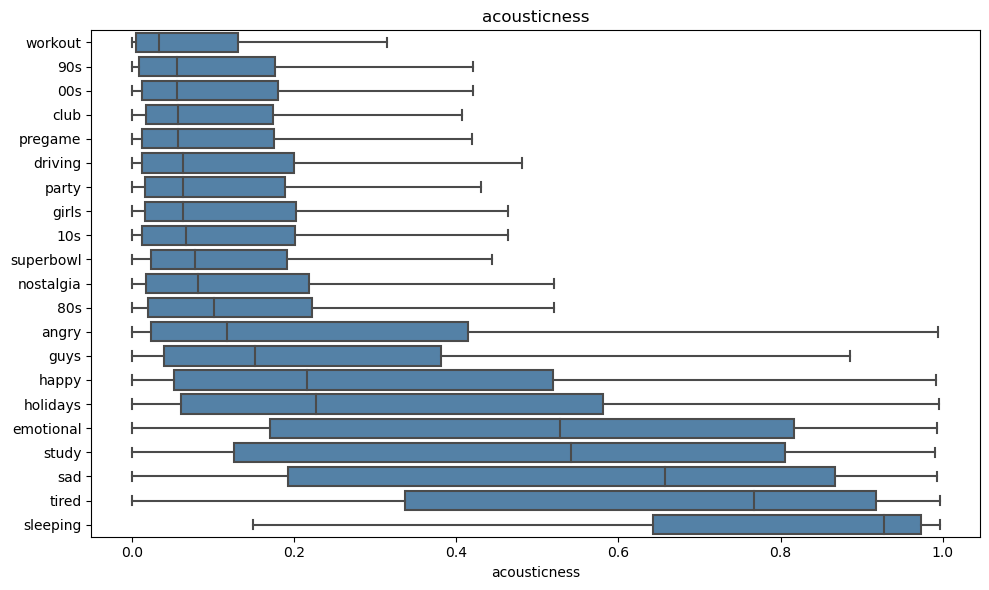

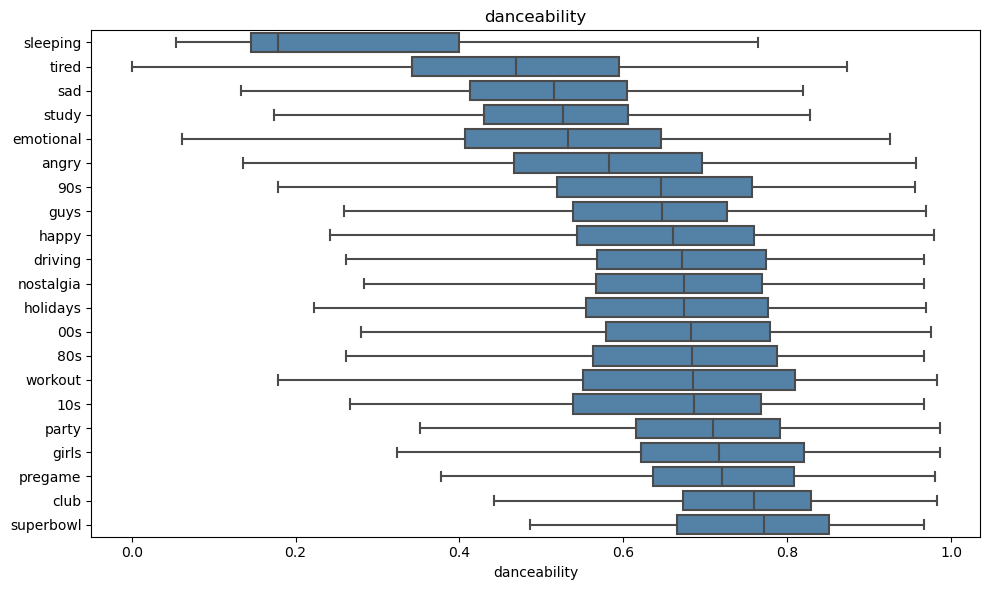

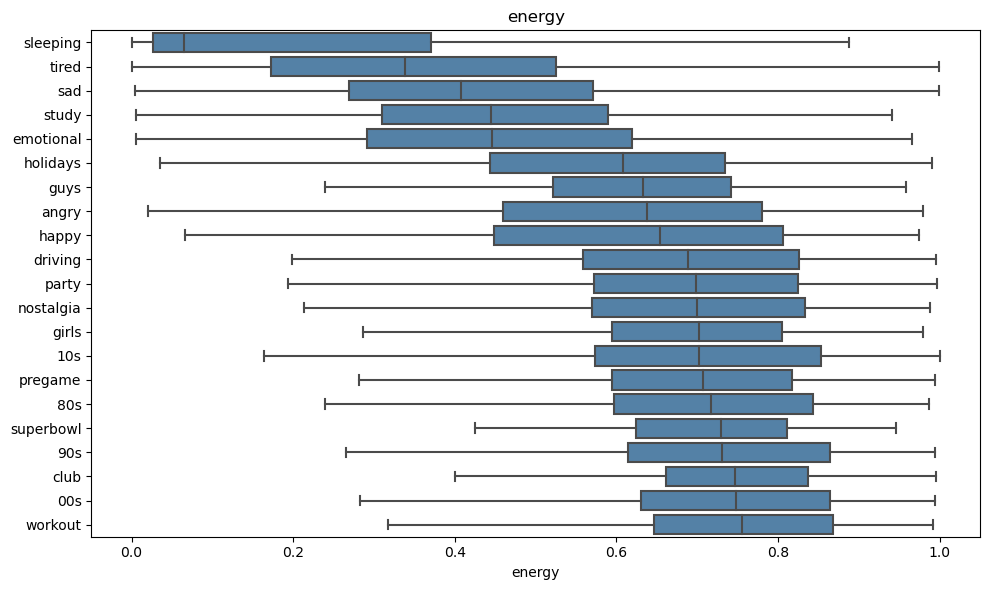

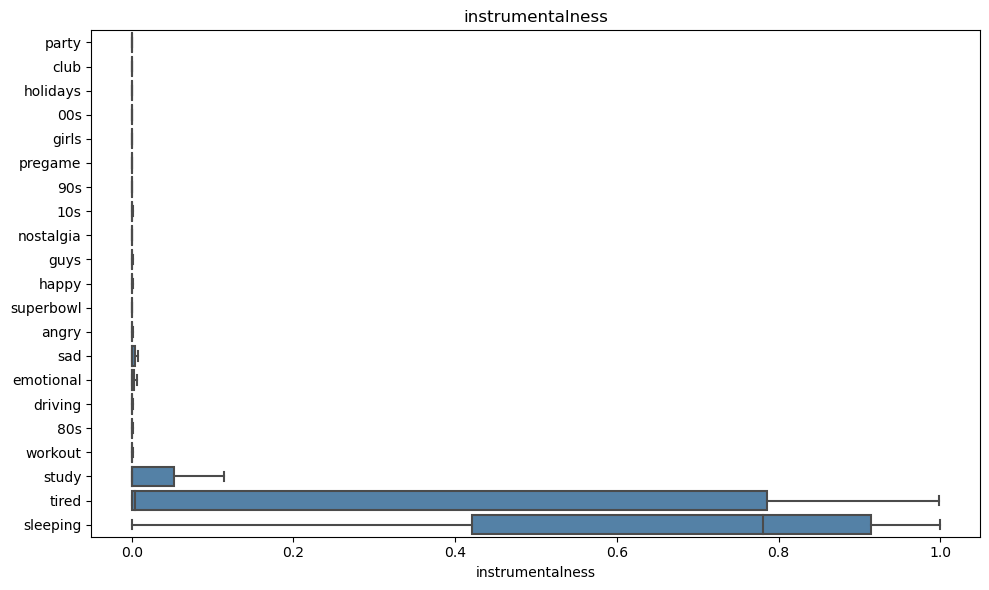

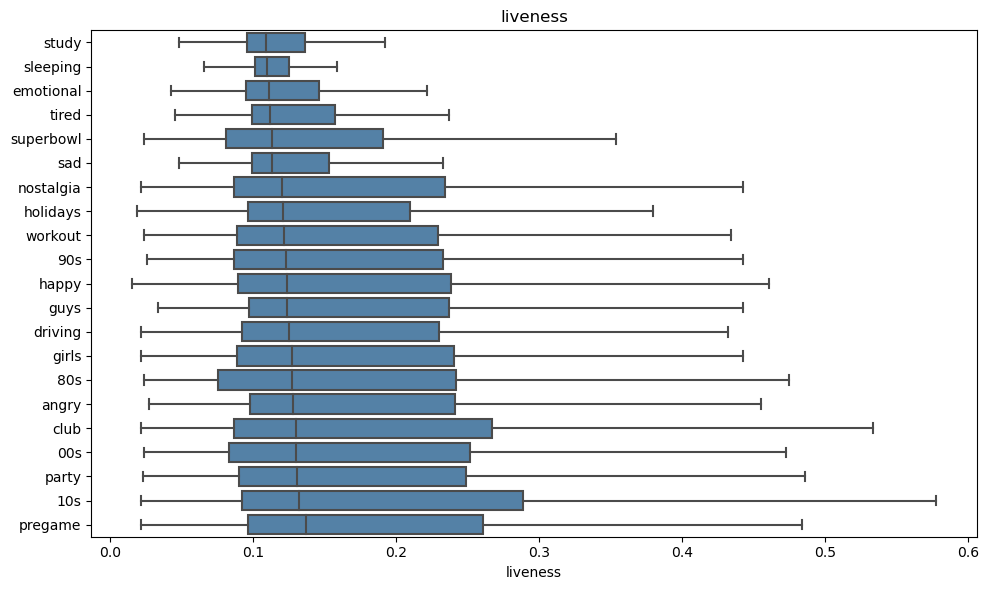

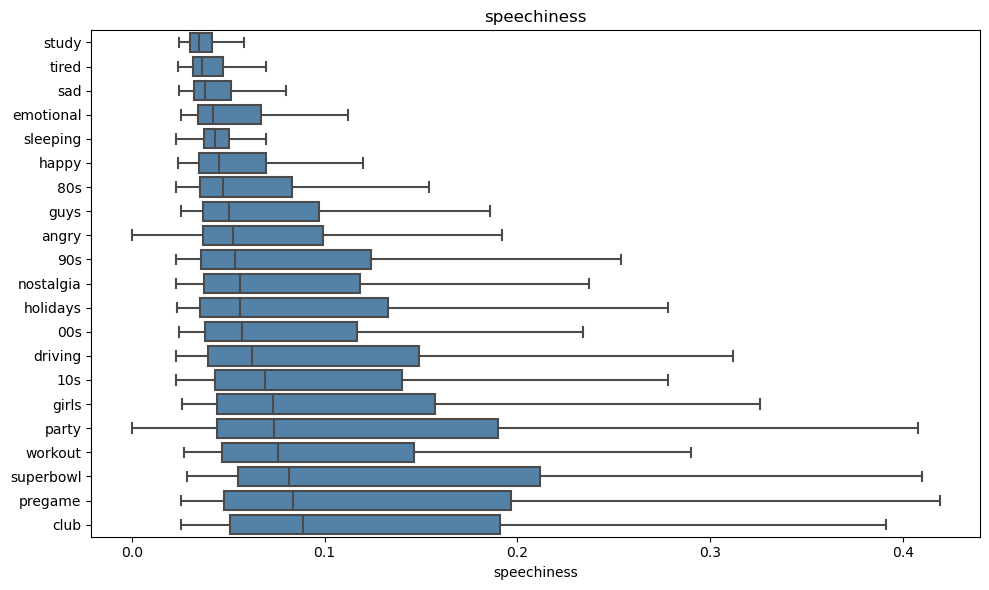

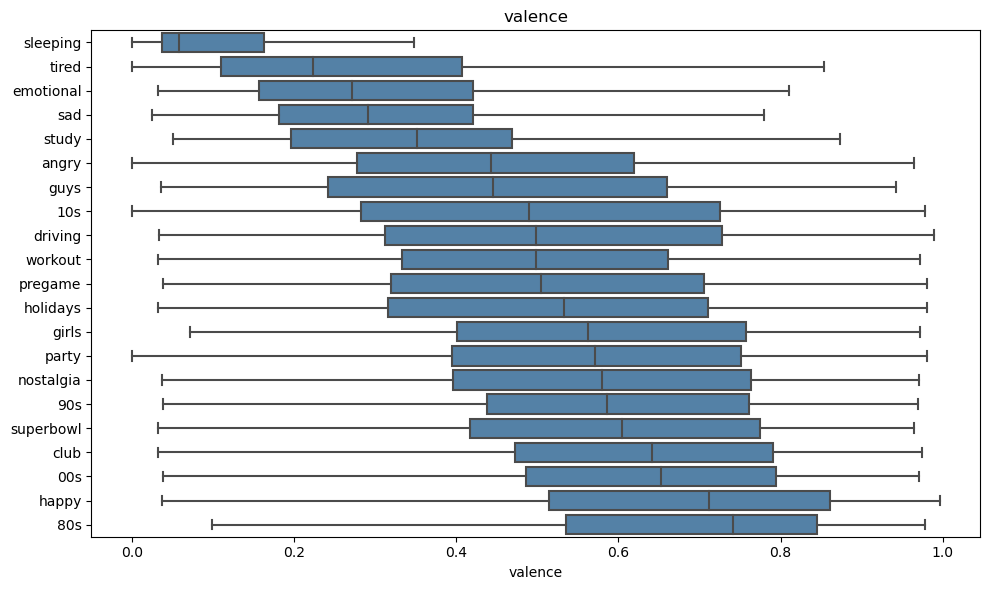

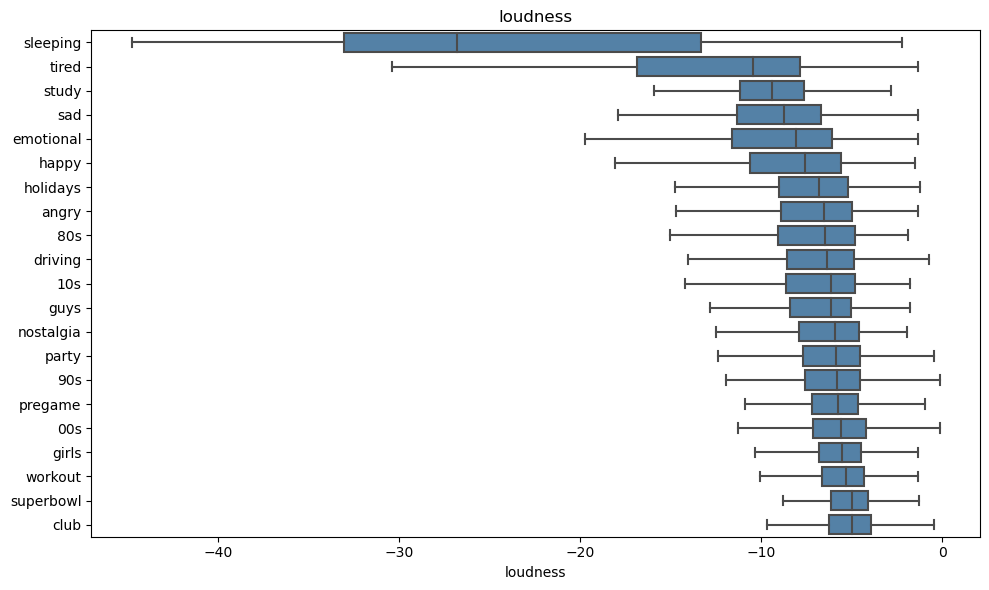

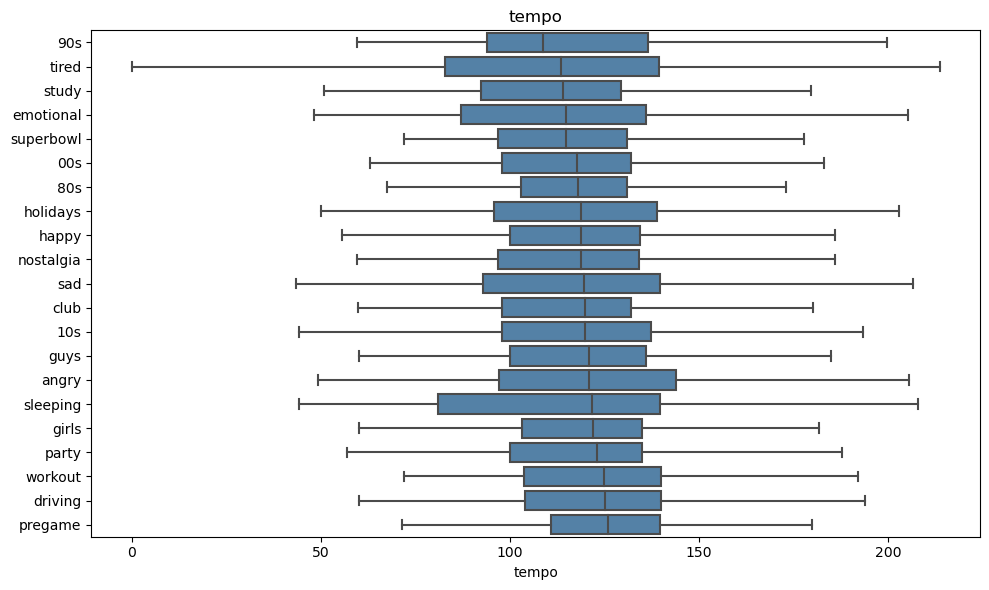

In [13]:
PROFILE_COLS = AUDIO_FEATURES + ["popularity"]
kw_means = df_kw.groupby("keyword")[PROFILE_COLS].mean()
kw_means["major_share"] = df_kw.groupby("keyword")["mode"].mean()
for f in AUDIO_FEATURES:
    fig, ax = plt.subplots(figsize=(10, 6))

    order = df_kw.groupby("keyword")[f].median().sort_values().index

    sns.boxplot(
        data=df_kw,
        y="keyword",
        x=f,
        order=order,
        ax=ax,
        showfliers=False,
        color="steelblue"
    )

    ax.set_title(f)
    ax.set_ylabel("")

    plt.tight_layout()
    plt.show()